# Lab 05: Predict late deliveries

Every number below comes from `python -m latedeliveries.train`. The test set was scored once, inside that script; this notebook only reads the saved reports.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from latedeliveries.data import make_orders

ROOT = Path.cwd().parent
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())
info = json.loads((ROOT / "models" / "model_info.json").read_text())

## How common are late orders?

In [2]:
orders = make_orders()
rate = orders["late"].mean()
print(f"{len(orders)} orders, {orders['late'].sum()} late ({rate:.1%})")
print()
print(orders.isna().mean().round(2).loc[lambda s: s > 0].rename("share missing"))

3000 orders, 468 late (15.6%)

prep_minutes       0.06
customer_rating    0.50
Name: share missing, dtype: float64


About one order in six is late, so accuracy is a poor guide: a model that never flags anything is right 84% of the time and saves nothing.

## Model comparison (5-fold stratified CV, training data only)

In [3]:
cv = pd.read_csv(ROOT / "reports" / "cv_results.csv")


def pm(metric):
    return (
        cv[f"{metric}_mean"].round(3).astype(str)
        + " ± "
        + cv[f"{metric}_std"].round(3).astype(str)
    )


table = pd.DataFrame({"model": cv["model"]})
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    table[metric] = pm(metric)
table["best threshold"] = cv["cv_best_threshold"]
table["cv cost ($)"] = cv["cv_cost"]
table

,model,accuracy,precision,recall,f1,roc_auc,best threshold,cv cost ($)
0,dummy_prior,0.844 ± 0.001,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.5 ± 0.0,0.20,5265
1,logreg,0.862 ± 0.009,0.654 ± 0.065,0.242 ± 0.053,0.352 ± 0.064,0.795 ± 0.034,0.30,4031
2,logreg_balanced,0.737 ± 0.019,0.333 ± 0.027,0.681 ± 0.049,0.447 ± 0.034,0.795 ± 0.034,0.70,4098
3,random_forest,0.86 ± 0.005,0.754 ± 0.064,0.151 ± 0.032,0.25 ± 0.046,0.786 ± 0.036,0.25,4180
4,hist_gradient_boosting,0.851 ± 0.006,0.544 ± 0.036,0.288 ± 0.037,0.375 ± 0.036,0.754 ± 0.024,0.30,4327


Precision, recall and F1 here use the default 0.5 cut-off, so they are not the numbers the company will see. The last two columns use each model's own best threshold on out-of-fold predictions and are what the choice rests on.

## Cost against threshold (out-of-fold, training data)

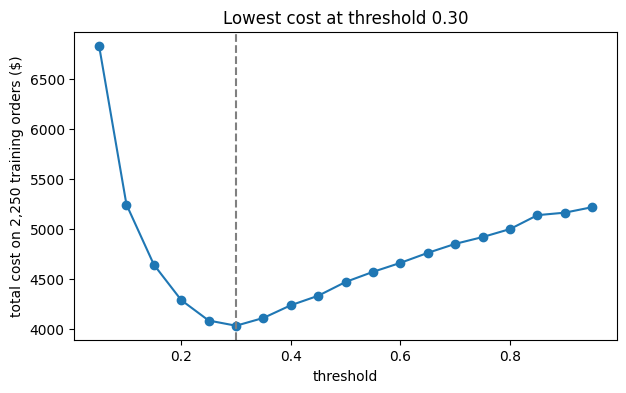

In [4]:
tc = pd.read_csv(ROOT / "reports" / "threshold_costs.csv")
best = tc.loc[tc["cost"].idxmin()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tc["threshold"], tc["cost"], marker="o")
ax.axvline(best["threshold"], color="grey", linestyle="--")
ax.set_xlabel("threshold")
ax.set_ylabel("total cost on 2,250 training orders ($)")
ax.set_title(f"Lowest cost at threshold {best['threshold']:.2f}")
plt.show()

## Confusion matrix on the test set

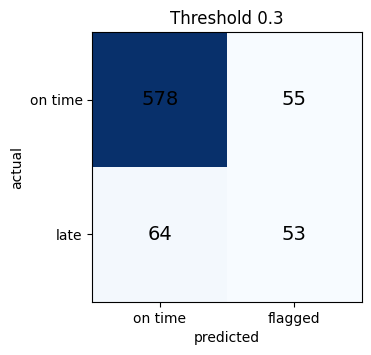

accuracy     0.841
precision    0.491
recall       0.453
f1           0.471
roc_auc      0.796
dtype: float64

In [5]:
cm = metrics["test_metrics"]["confusion_matrix"]
grid = [[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]]
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(grid, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, grid[i][j], ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1], labels=["on time", "flagged"])
ax.set_yticks([0, 1], labels=["on time", "late"])
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title(f"Threshold {metrics['threshold']}")
plt.show()
pd.Series(
    {
        k: round(v, 3)
        for k, v in metrics["test_metrics"].items()
        if k != "confusion_matrix"
    }
)

## Cost of the three policies on the test set

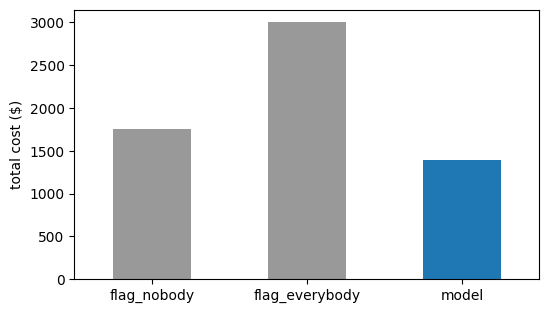

Model saves $363 against flag-nobody (20.7%).


flag_nobody       1755
flag_everybody    3000
model             1392
dtype: int64

In [6]:
policies = pd.Series(metrics["policy_costs"])
saving = policies["flag_nobody"] - policies["model"]
fig, ax = plt.subplots(figsize=(6, 3.5))
policies.plot.bar(ax=ax, rot=0, color=["#999999", "#999999", "#1f77b4"])
ax.set_ylabel("total cost ($)")
plt.show()
print(
    f"Model saves ${saving} against flag-nobody "
    f"({saving / policies['flag_nobody']:.1%})."
)
policies

## Leakage check

In [7]:
leak = json.loads((ROOT / "reports" / "leakage_check.json").read_text())
leak

{'cv_roc_auc_without_customer_rating': 0.7952382080288983,
 'cv_roc_auc_with_customer_rating': 0.9072241944934432}

Adding `customer_rating` lifts cross-validated ROC-AUC from 0.795 to 0.907. Customers rate after the delivery, so the jump is the outcome leaking back in. The column stays out.

## Recommendation

**Would I use this model?** Yes, as a cheap first step. On 750 unseen orders it cost $1,392, against $1,755 for flagging nobody and $3,000 for flagging everybody: a saving of $363 (21%).

**Why this threshold?** 0.30 had the lowest cost on out-of-fold training predictions. A voucher costs $4 and a missed late order $15, so flagging pays once the chance of lateness passes roughly 27%.

**What was excluded?** `customer_rating` (given after delivery, leaks the outcome) and `order_id` (a label only).

**One limitation.** The model catches only 45% of late orders and about half of its flags are wasted. The test set has 117 late orders, so the saving is uncertain and should be checked on live orders before rollout.